In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()
engine = create_engine(os.getenv("DATABASE_URL"))

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

print("✅ Setup selesai!")

✅ Setup selesai!


In [ ]:
query = "SELECT * FROM sales;"
df = pd.read_sql_query(query, engine)

print(f"Data berhasil ditarik: {len(df)} baris.")
display(df.head())

Data berhasil ditarik: 1000 baris.


,sale_id,branch,city,customer_type,is_member,gender,product_name,product_category,unit_price,quantity,tax,total_price,revenue_per_item,reward_points,reward_rate,basket_size_segment,transaction_segment
0,1,A,New York,Member,True,Male,Shampoo,Personal Care,5.50,3,1.16,17.66,5.89,1,0.0566,Small,Low
1,2,B,Los Angeles,Normal,False,Female,Notebook,Stationery,2.75,10,1.93,29.43,2.94,0,0.0000,Medium,Low
2,3,A,New York,Member,True,Female,Apple,Fruits,1.20,15,1.26,19.26,1.28,1,0.0519,Large,Low
3,4,A,Chicago,Normal,False,Male,Detergent,Household,7.80,5,2.73,41.73,8.35,0,0.0000,Small,Low
4,5,B,Los Angeles,Member,True,Female,Orange Juice,Beverages,3.50,7,1.72,26.22,3.75,2,0.0763,Medium,Low


/tmp/ipykernel_69376/3387761324.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=city_stats, x="city", y="total_revenue", ax=ax1, palette="Blues_d")


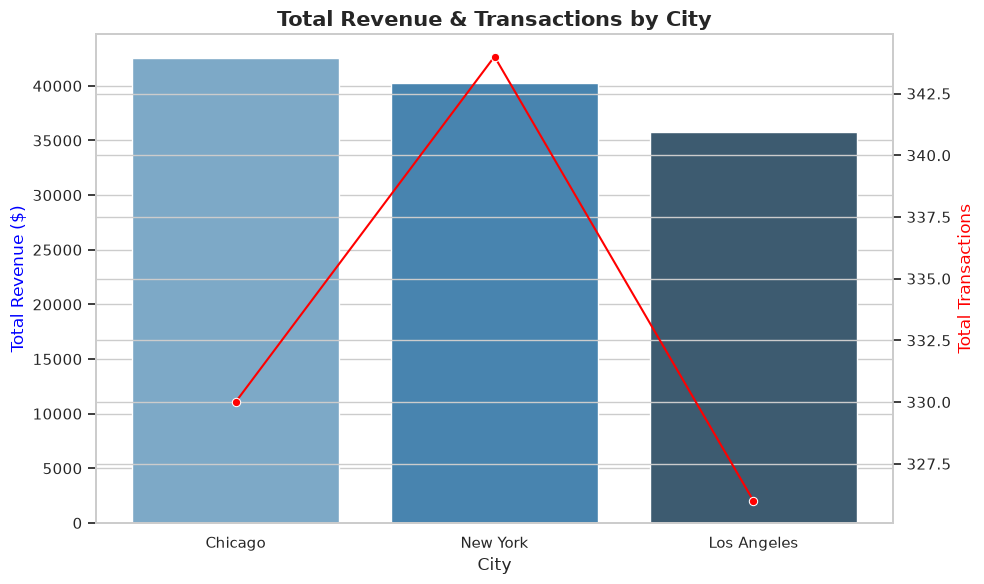

In [ ]:
city_stats = df.groupby("city").agg(
    total_revenue=("total_price", "sum"),
    total_transactions=("sale_id", "count")
).reset_index().sort_values("total_revenue", ascending=False)

fig, ax1 = plt.subplots()

sns.barplot(data=city_stats, x="city", y="total_revenue", ax=ax1, palette="Blues_d")
ax1.set_ylabel("Total Revenue ($)", color="blue")
ax1.set_xlabel("City")
ax1.set_title("Total Revenue & Transactions by City", fontsize=15, fontweight="bold")

ax2 = ax1.twinx()
sns.lineplot(data=city_stats, x="city", y="total_transactions", ax=ax2, color="red", marker="o", sort=False)
ax2.set_ylabel("Total Transactions", color="red")

plt.tight_layout()
plt.savefig("../docs/revenue_by_city.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_69376/2094714698.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_stats, x="total_price", y="product_category", palette="magma")


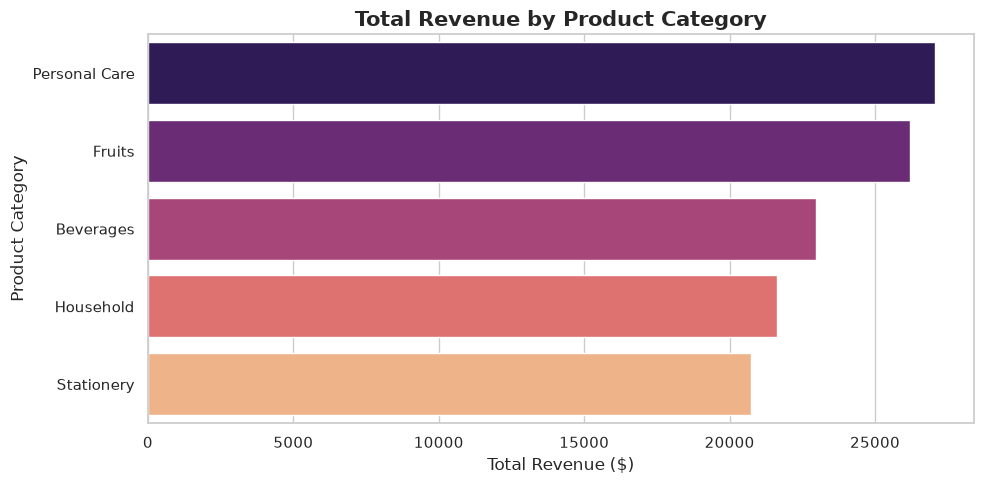

In [ ]:
cat_stats = df.groupby("product_category")["total_price"].sum().reset_index().sort_values("total_price", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=cat_stats, x="total_price", y="product_category", palette="magma")
plt.title("Total Revenue by Product Category", fontsize=15, fontweight="bold")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.savefig("../docs/revenue_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

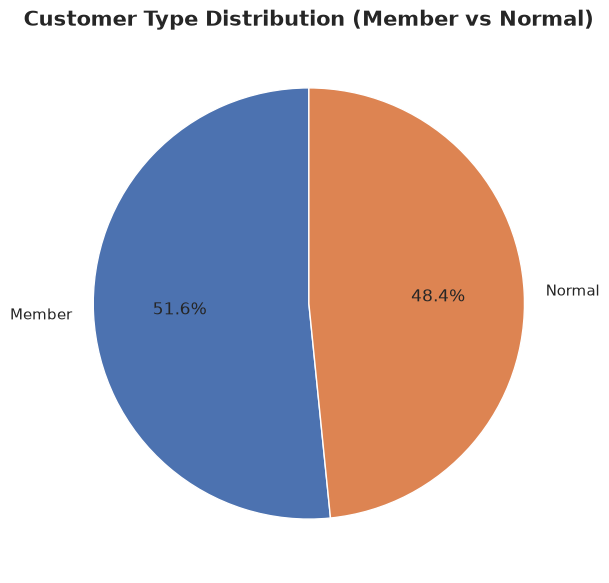

In [ ]:
member_counts = df["customer_type"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(member_counts, labels=member_counts.index, autopct="%1.1f%%", startangle=90, colors=["#4C72B0", "#DD8452"])
plt.title("Customer Type Distribution (Member vs Normal)", fontsize=15, fontweight="bold")

plt.savefig("../docs/customer_distribution.png", dpi=300, bbox_inches="tight")
plt.show()